Comparing ANN, RNN, LSTM, GRU, and BiLSTM for 3-class tweet sentiment classification with leakage-free group splits


**1. Setup Lingkungan**

In [ ]:
import os, re, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


**2. Upload Dataset**

In [ ]:
FILE_NAME = "training.csv"

try:
    from google.colab import files
    if not os.path.exists(FILE_NAME):
        uploaded = files.upload()
        FILE_NAME = list(uploaded.keys())[0]
except ImportError:
    pass

COLS = ["id", "entity", "sentiment", "text"]
df_raw = pd.read_csv(FILE_NAME, header=None, names=COLS)
print("Ukuran dataset:", df_raw.shape)
df_raw.head()

Saving training.csv to training.csv
Ukuran dataset: (74682, 4)


,id,entity,sentiment,text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [ ]:
df_raw.info()
print("\nmissing values:\n" ,df_raw.isnull().sum())
print("\njumlah ID tweet unik :", df_raw.id.nunique())
print("Rata rata baris per ID:", round(len(df_raw) / df_raw["id"].nunique(), 2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         74682 non-null  int64 
 1   entity     74682 non-null  object
 2   sentiment  74682 non-null  object
 3   text       73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB

missing values:
 id             0
entity         0
sentiment      0
text         686
dtype: int64

jumlah ID tweet unik : 12447
Rata rata baris per ID: 6.0


In [ ]:
INCLUDE_IRRELEVANT = False

df = df_raw[["id", "text", "sentiment"]].copy()
df = df.dropna(subset=["text"])
if not INCLUDE_IRRELEVANT:
    df = df[df["sentiment"] != "Irrelevant"]
df = df.reset_index(drop=True)
print("Ukuran setelah seleksi:", df.shape)
df.head()

Ukuran setelah seleksi: (61121, 3)


,id,text,sentiment
0,2401,im getting on borderlands and i will murder yo...,Positive
1,2401,I am coming to the borders and I will kill you...,Positive
2,2401,im getting on borderlands and i will kill you ...,Positive
3,2401,im coming on borderlands and i will murder you...,Positive
4,2401,im getting on borderlands 2 and i will murder ...,Positive


Distribusi label:
sentiment
Negative    22358
Positive    20655
Neutral     18108
Name: count, dtype: int64

Proporsi (%):
sentiment
Negative    36.58
Positive    33.79
Neutral     29.63
Name: proportion, dtype: float64


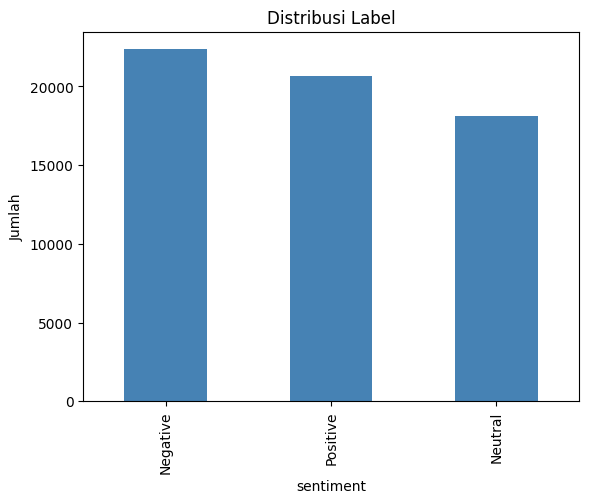


Contoh baris dengan id = 2401:
 - im getting on borderlands and i will murder you all ,
 - I am coming to the borders and I will kill you all,
 - im getting on borderlands and i will kill you all,
 - im coming on borderlands and i will murder you all,
 - im getting on borderlands 2 and i will murder you me all,
 - im getting into borderlands and i can murder you all,


In [ ]:
print("Distribusi label:")
print(df["sentiment"].value_counts())
print("\nProporsi (%):")
print((df["sentiment"].value_counts(normalize=True) * 100).round(2))

df["sentiment"].value_counts().plot(kind="bar", color="steelblue", title="Distribusi Label")
plt.ylabel("Jumlah"); plt.show()

contoh_id = df["id"].iloc[0]
print(f"\nContoh baris dengan id = {contoh_id}:")
for t in df.loc[df["id"] == contoh_id, "text"]:
    print(" -", t[:110])

**3. Prepocessing**

In [ ]:
def preprocess(text):
    text = str(text).lower()                                  # case folding
    text = re.sub(r"http\S+|www\.\S+|pic\.twitter\.com\S+", " ", text)   # URL
    text = re.sub(r"@\w+", " ", text)                          # mention
    text = re.sub(r"&\w+;", " ", text)                         # entitas HTML (&amp; dll)
    text = text.replace("n't", " not")                         # don't -> do not
    text = re.sub(r"[^a-z\s]", " ", text)                      # buang angka & tanda baca
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(preprocess)
df = df[df["clean_text"].str.len() > 0]
df = df.drop_duplicates(subset=["clean_text", "sentiment"]).reset_index(drop=True)

print("Ukuran setelah preprocessing & hapus duplikat:", df.shape)
df[["text", "clean_text", "sentiment"]].head()

Ukuran setelah preprocessing & hapus duplikat: (54942, 4)


,text,clean_text,sentiment
0,im getting on borderlands and i will murder yo...,im getting on borderlands and i will murder yo...,Positive
1,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...,Positive
2,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you all,Positive
3,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...,Positive
4,im getting on borderlands 2 and i will murder ...,im getting on borderlands and i will murder yo...,Positive


**4. Train, Validation, Test Split**

In [ ]:
le = LabelEncoder()
df["label"] = le.fit_transform(df["sentiment"])
CLASS_NAMES = list(le.classes_)
NUM_CLASSES = len(CLASS_NAMES)
print("Kelas:", dict(enumerate(CLASS_NAMES)))

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trval_idx, test_idx = next(gss.split(df, groups=df["id"]))
df_trval, df_test = df.iloc[trval_idx], df.iloc[test_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=SEED)   # 0.125 x 80% = 10%
tr_idx, val_idx = next(gss2.split(df_trval, groups=df_trval["id"]))
df_train, df_val = df_trval.iloc[tr_idx], df_trval.iloc[val_idx]

print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")
print("ID yang bocor train∩test:", len(set(df_train.id) & set(df_test.id)))
print("ID yang bocor train∩val :", len(set(df_train.id) & set(df_val.id)))

Kelas: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
Train: 38430 | Val: 5535 | Test: 10977
ID yang bocor train∩test: 0
ID yang bocor train∩val : 0


**5. Tokenisasi dan Padding**

In [ ]:
lengths = df_train["clean_text"].str.split().str.len()
print(lengths.describe())

VOCAB_SIZE = 20000
MAX_LEN = int(np.percentile(lengths, 95))     # mencakup 95% kalimat
print("MAX_LEN =", MAX_LEN)

vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE,
                                      output_sequence_length=MAX_LEN,
                                      standardize=None)
vectorizer.adapt(df_train["clean_text"].values)
VOCAB = len(vectorizer.get_vocabulary())
print("Ukuran kosakata:", VOCAB)

def to_seq(texts):
    return vectorizer(np.array(texts)).numpy()

X_train, X_val, X_test = (to_seq(d["clean_text"].values) for d in (df_train, df_val, df_test))
y_train, y_val, y_test = (d["label"].values for d in (df_train, df_val, df_test))

print("Bentuk X_train:", X_train.shape)
print("Contoh:", df_train["clean_text"].iloc[0])
print("Sekuens:", X_train[0])

count    38430.000000
mean        19.726282
std         13.664611
min          1.000000
25%          9.000000
50%         16.000000
75%         27.000000
max        166.000000
Name: clean_text, dtype: float64
MAX_LEN = 48
Ukuran kosakata: 20000
Bentuk X_train: (38430, 48)
Contoh: so i spent a few hours making something for fun if you do not know i am a huge fan and maya is one of my favorite characters so i decided to make myself a wallpaper for my pc here is the original image versus the creation i made enjoy
Sekuens: [   21     3   650     6   332   317   287   231    11   122    46    14
    33    16   118     3   106     6   422   682     5  4265     9    47
     7    13   303   725    21     3   618     4   126   503     6  5431
    11    13   279   113     9     2   611  2066  4384     2 10288     3]


**6. Model Neural**

In [ ]:
EMB_DIM = 100

def build_model(kind, units, dropout):
    inp = keras.Input(shape=(MAX_LEN,), dtype="int32")
    x = layers.Embedding(VOCAB, EMB_DIM, mask_zero=True)(inp)
    if kind == "ANN":
        x = layers.GlobalAveragePooling1D()(x)
        x = layers.Dense(units, activation="relu")(x)
    elif kind == "RNN":
        x = layers.SimpleRNN(units)(x)
    elif kind == "LSTM":
        x = layers.LSTM(units)(x)
    elif kind == "GRU":
        x = layers.GRU(units)(x)
    elif kind == "BiLSTM":
        x = layers.Bidirectional(layers.LSTM(units))(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inp, out, name=kind)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_model("BiLSTM", 64, 0.3).summary()

Model: "BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 48)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 48, 100)   │  2,000,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 48)        │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 128)       │     84,480 │ embedding_1[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        387 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,084,867 (7.95 MB)

 Trainable params: 2,084,867 (7.95 MB)

 Non-trainable params: 0 (0.00 B)

**7. Training dan Tuning**

In [ ]:
MODEL_KINDS = ["ANN", "RNN", "LSTM", "GRU", "BiLSTM"]
VARIANTS = {"V1": dict(units=64,  dropout=0.3),
            "V2": dict(units=128, dropout=0.5)}
EPOCHS = 15
BATCH_SIZE = 128

trained, histories, run_log = {}, {}, []

for kind in MODEL_KINDS:
    for vname, cfg in VARIANTS.items():
        tag = f"{kind}-{vname}"
        print(f"\n===== {tag}  {cfg} =====")
        keras.backend.clear_session(); tf.random.set_seed(SEED)
        model = build_model(kind, **cfg)
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                           restore_best_weights=True)
        t0 = time.time()
        hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                         epochs=EPOCHS, batch_size=BATCH_SIZE,
                         callbacks=[es], verbose=2)
        val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
        trained[tag], histories[tag] = model, hist.history
        run_log.append({"Model": kind, "Variasi": vname, **cfg,
                        "Epoch dijalankan": len(hist.history["loss"]),
                        "Val Accuracy": val_acc, "Val Loss": val_loss,
                        "Waktu (s)": round(time.time() - t0, 1)})

tuning_df = pd.DataFrame(run_log)
tuning_df


===== ANN-V1  {'units': 64, 'dropout': 0.3} =====
Epoch 1/15
301/301 - 9s - 29ms/step - accuracy: 0.6932 - loss: 0.7444 - val_accuracy: 0.6089 - val_loss: 0.9494
Epoch 2/15
301/301 - 6s - 20ms/step - accuracy: 0.8890 - loss: 0.3424 - val_accuracy: 0.5595 - val_loss: 1.2730
Epoch 3/15
301/301 - 7s - 24ms/step - accuracy: 0.9353 - loss: 0.2172 - val_accuracy: 0.5377 - val_loss: 1.5906

===== ANN-V2  {'units': 128, 'dropout': 0.5} =====
Epoch 1/15
301/301 - 8s - 28ms/step - accuracy: 0.6996 - loss: 0.7293 - val_accuracy: 0.6000 - val_loss: 0.9776
Epoch 2/15
301/301 - 6s - 21ms/step - accuracy: 0.8956 - loss: 0.3255 - val_accuracy: 0.5521 - val_loss: 1.3282
Epoch 3/15
301/301 - 11s - 37ms/step - accuracy: 0.9363 - loss: 0.2123 - val_accuracy: 0.5342 - val_loss: 1.6547

===== RNN-V1  {'units': 64, 'dropout': 0.3} =====
Epoch 1/15
301/301 - 18s - 60ms/step - accuracy: 0.7346 - loss: 0.6309 - val_accuracy: 0.5845 - val_loss: 1.0682
Epoch 2/15
301/301 - 15s - 49ms/step - accuracy: 0.9395 - lo

,Model,Variasi,units,dropout,Epoch dijalankan,Val Accuracy,Val Loss,Waktu (s)
0,ANN,V1,64,0.3,3,0.608853,0.949388,22.7
1,ANN,V2,128,0.5,3,0.600000,0.977594,26.6
2,RNN,V1,64,0.3,3,0.584463,1.068235,48.2
3,RNN,V2,128,0.5,3,0.584824,1.127951,98.0
4,LSTM,V1,64,0.3,3,0.596929,1.067322,108.7
5,LSTM,V2,128,0.5,3,0.592231,1.087988,199.9
6,GRU,V1,64,0.3,3,0.580849,1.108647,120.7
7,GRU,V2,128,0.5,3,0.577236,1.115029,193.8
8,BiLSTM,V1,64,0.3,3,0.587353,1.099705,198.9
9,BiLSTM,V2,128,0.5,3,0.586631,1.032865,304.4


**8. Kurva Training**

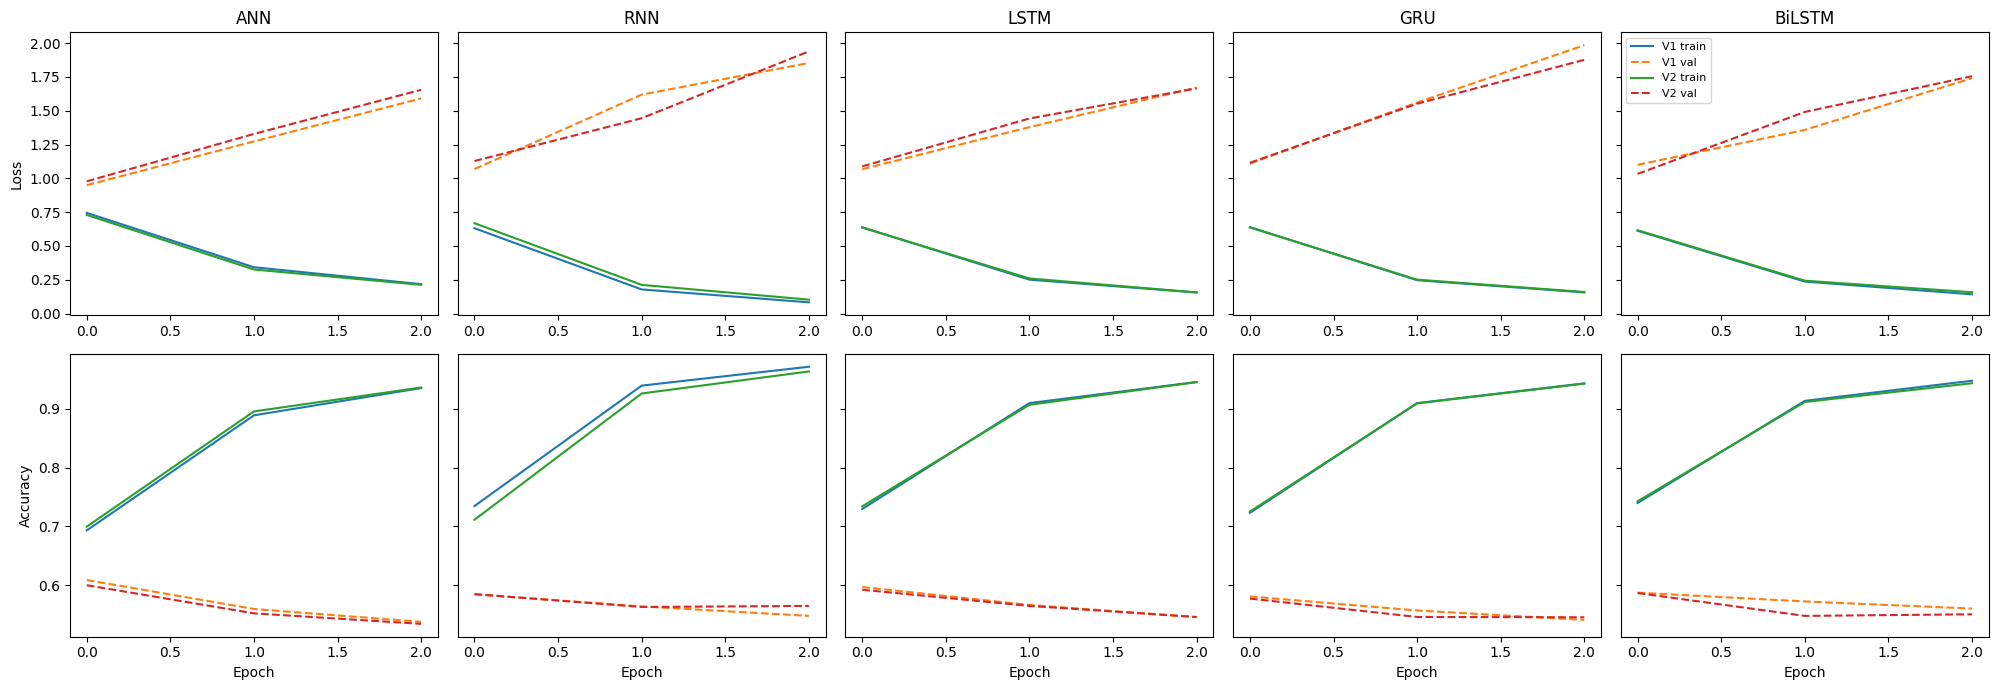

In [ ]:
fig, axes = plt.subplots(2, len(MODEL_KINDS), figsize=(4 * len(MODEL_KINDS), 7), sharey="row")
for j, kind in enumerate(MODEL_KINDS):
    for vname in VARIANTS:
        h = histories[f"{kind}-{vname}"]
        axes[0, j].plot(h["loss"], label=f"{vname} train")
        axes[0, j].plot(h["val_loss"], "--", label=f"{vname} val")
        axes[1, j].plot(h["accuracy"], label=f"{vname} train")
        axes[1, j].plot(h["val_accuracy"], "--", label=f"{vname} val")
    axes[0, j].set_title(kind)
    axes[1, j].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss"); axes[1, 0].set_ylabel("Accuracy")
axes[0, -1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
best_variant = (tuning_df.sort_values("Val Accuracy", ascending=False)
                         .groupby("Model").head(1).set_index("Model")["Variasi"].to_dict())
best_variant = {k: best_variant[k] for k in MODEL_KINDS}
print(best_variant)

{'ANN': 'V1', 'RNN': 'V2', 'LSTM': 'V1', 'GRU': 'V1', 'BiLSTM': 'V1'}


**9. Prediksi dan evluasi pada data test**

In [ ]:
predictions = {}
for kind in MODEL_KINDS:
    tag = f"{kind}-{best_variant[kind]}"
    predictions[tag] = np.argmax(trained[tag].predict(X_test, verbose=0), axis=1)

results = []
for name, preds in predictions.items():
    acc = accuracy_score(y_test, preds)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_test, preds, average="weighted", zero_division=0)
    _, _, f_m, _ = precision_recall_fscore_support(y_test, preds, average="macro", zero_division=0)
    results.append({"Model": name, "Accuracy": acc, "Precision": p_w,
                    "Recall": r_w, "F1-score": f_w, "F1 (macro)": f_m})

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df.style.format({c: "{:.4f}" for c in results_df.columns if c != "Model"}).highlight_max(
    subset=["Accuracy", "Precision", "Recall", "F1-score", "F1 (macro)"], color="lightgreen")

,Model,Accuracy,Precision,Recall,F1-score,F1 (macro)
0,ANN-V1,0.6276,0.6276,0.6276,0.6262,0.6211
1,LSTM-V1,0.6170,0.6156,0.6170,0.6145,0.6087
2,BiLSTM-V1,0.6004,0.5994,0.6004,0.5987,0.5925
3,GRU-V1,0.5972,0.5955,0.5972,0.5938,0.5870
4,RNN-V2,0.5986,0.6001,0.5986,0.5911,0.5836


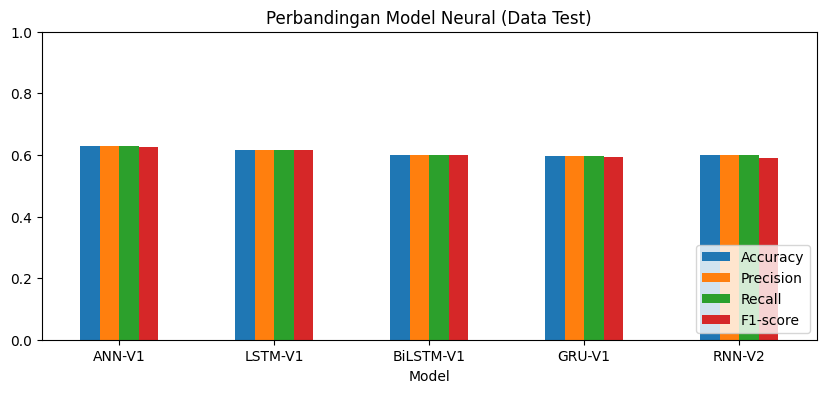

In [ ]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 4), ylim=(0, 1), title="Perbandingan Model Neural (Data Test)")
plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()

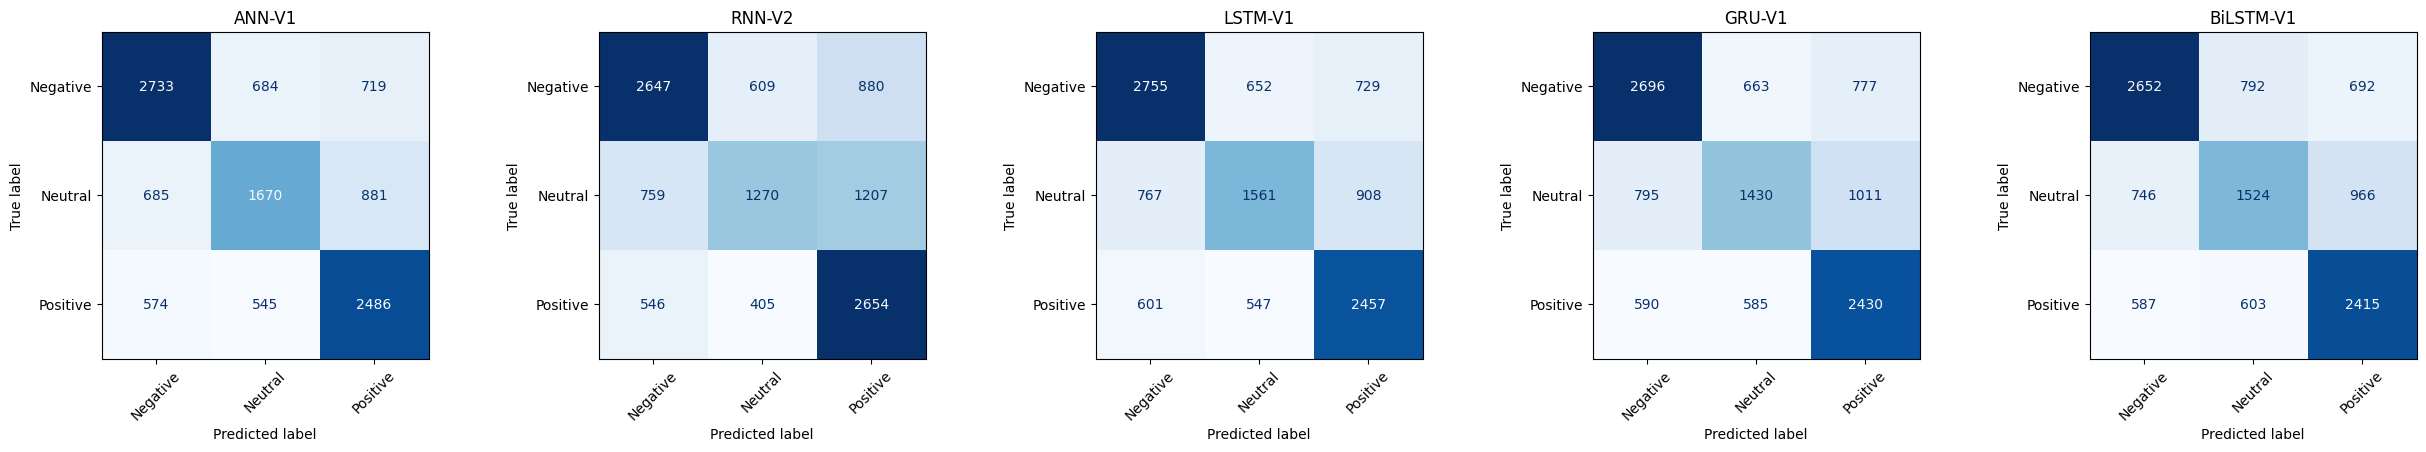

In [ ]:
fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 4.5))
for ax, (name, preds) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [ ]:
best_name = results_df.iloc[0]["Model"]
print(f"Classification report — model terbaik: {best_name}\n")
print(classification_report(y_test, predictions[best_name], target_names=CLASS_NAMES, digits=4))

Classification report — model terbaik: ANN-V1

              precision    recall  f1-score   support

    Negative     0.6846    0.6608    0.6725      4136
     Neutral     0.5761    0.5161    0.5444      3236
    Positive     0.6084    0.6896    0.6465      3605

    accuracy                         0.6276     10977
   macro avg     0.6230    0.6222    0.6211     10977
weighted avg     0.6276    0.6276    0.6262     10977

